# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:** Паскин Владислав Романович | **Период данных:** 2024-01-01 - 2025-06-30 | **Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html

Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 200)

clean = pd.read_parquet("data/clean_data.parquet").set_index("client_id")
txn = pd.read_parquet("data/txn_clean.parquet")
txn["month"] = txn["txn_datetime"].dt.to_period("M")

metric = clean[clean["base_months"] >= 3]        # клиенты, у которых считается изменение
full12 = metric[metric["base_months"] == 12]     # с полным 2024 - для помесячных графиков

## 1. Главное

1. С января 2025 у 1508 из 5029 клиентов (30%) операций по карте в месяц стало меньше на 45% и больше - примерно втрое, и к лету падение продолжается. У остальных 70% картой пользуются как раньше, с обычным сезоном.
2. Снижение сосредоточено в массовом сегменте: снизились 43.6% массовых клиентов против 12.6-15.1% в остальных сегментах, а среди массовых без мобильного приложения - 58.8%.
3. Снизившиеся реже пользуются картой сразу во всех каналах и категориях, отказов по картам не больше (1.88% операций в 2024 и 1.95% в 2025). Похоже, что траты ушли на карту другого банка: снизившихся больше среди тех, у кого зарплата в другом банке или источник не указан (34.2% и 37.5% против 22.6% с зарплатой в нашем банке).
4. Отдельная история: 234 клиента почти перестали платить картой за развлечения (медиана 2.17 -> 0.17 операции в месяц), остальные траты у них на месте.
5. Для кампании - 4 группы, 1551 клиент с согласием на коммуникацию: массовые без приложения (535), массовые с приложением (481), зарплатные, премиальные и Private (301), ушедшие из развлечений (234).

## 2. Контекст

Банк видит, что за последние полгода клиенты стали реже пользоваться картами, и готовит кампанию по возврату активности на 2000 клиентов. Нужно понять, к кому идти: 3-5 групп от 150 человек, каждая описана правилом по признакам клиента, и для каждой - за счет чего упало, чтобы подготовить отдельное предложение. Писать можно только клиентам с согласием на коммуникацию.

## 3. Данные и ограничения

Период - 2024-01-01 - 2025-06-30: базовый период - 2024 год, оцениваемый - январь-июнь 2025. Клиенты - 5612 действующих на 30.06.2025 (после удаления дублей), операции - 584771 за период по этим клиентам. Убраны 84 операции вне периода и 30440 операций 388 клиентов, которых нет в справочнике: это ушедшие из банка (последняя операция у всех до 2025-04), предложить им ничего нельзя.

**Метрика активности** - число операций клиента по карте в месяц (все статусы): заказчик видит, что картой стали пользоваться реже, это прямо частота. Для каждого клиента сравниваем среднее за январь-июнь 2025 со средним за 2024, считая 2024 с первого полного месяца после открытия текущей карты (в данных только операции по текущей карте). Изменение считается у 5029 клиентов, у которых в 2024 было хотя бы 3 полных месяца карты; у 583 карта открыта с 2024-10, сравнить не с чем. "Снизился" - операций меньше на 45% и больше (провал между двумя пиками распределения, 4.2). Метрика не увидит: падение сумм при той же частоте, перенос крупных трат в другой банк при сохранении мелких, падение только в последний месяц, клиента с большим числом отказов (он выглядит активным).

Чего в данных нет: причин снижения (опросов, обращений, закрытий карт), операций в других банках, курса для пересчета 0.4% операций в USD и EUR (суммы в отчете не используются). Оценка обслуживания есть только у 41.5% клиентов, возраст старше 88 лет обрезан.

## 4. Находки

<!-- По одной находке на подраздел. Заголовок подраздела — вывод,
     а не тема. Под заголовком: график или таблица, затем 2–4
     предложения. -->

### 4.1. С января 2025 у 30% клиентов операций втрое меньше, у остальных - обычный сезон

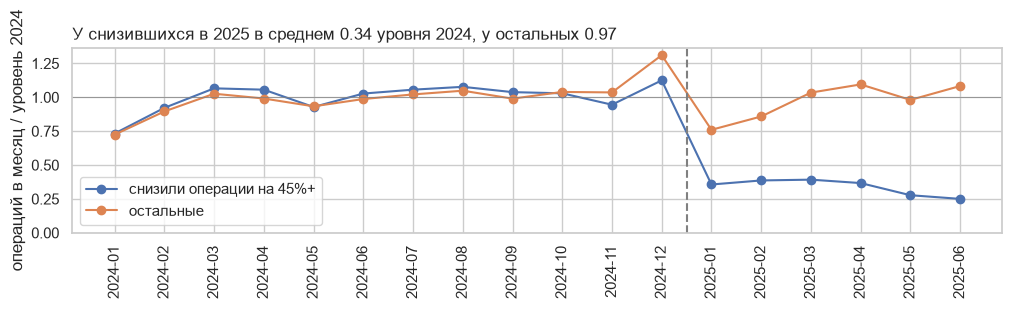

In [2]:
# операции в месяц относительно своего уровня 2024 (1 = как в 2024), клиенты с полным 2024
cnt = pd.crosstab(txn["client_id"], txn["month"]).reindex(full12.index, fill_value=0)
idx = cnt.div(full12["base_all"], axis=0)
traj = pd.DataFrame({
    "снизили операции на 45%+": idx[full12["dropped"]].mean(),
    "остальные": idx[~full12["dropped"]].mean(),
})
traj.index = traj.index.astype(str)

fig, ax = plt.subplots(figsize=(12, 2.4))
traj.plot(ax=ax, marker="o")
ax.axvline(11.5, color="gray", ls="--")
ax.axhline(1, color="gray", lw=0.5)
ax.set_xticks(range(len(traj)))
ax.set_xticklabels(traj.index, rotation=90)
ax.set_xlabel("")
ax.set_ylabel("операций в месяц / уровень 2024")
ax.set_ylim(0, None)
ax.set_title(f"У снизившихся в 2025 в среднем {traj.iloc[12:, 0].mean():.2f} уровня 2024, "
             f"у остальных {traj.iloc[12:, 1].mean():.2f}", loc="left")
plt.show()

Весь 2024 обе группы пользуются картой одинаково, с одним и тем же сезоном (январь - минимум, декабрь - максимум). В январе 2025 у снизившихся число операций обваливается ступенькой, держится на этом уровне до апреля и в мае-июне падает дальше. Падение не постепенное и одно и то же у всех подгрупп снизившихся - по сегменту, приложению, городу и возрасту.

### 4.2. Снизившиеся - отдельная группа клиентов, а не хвост общего распределения

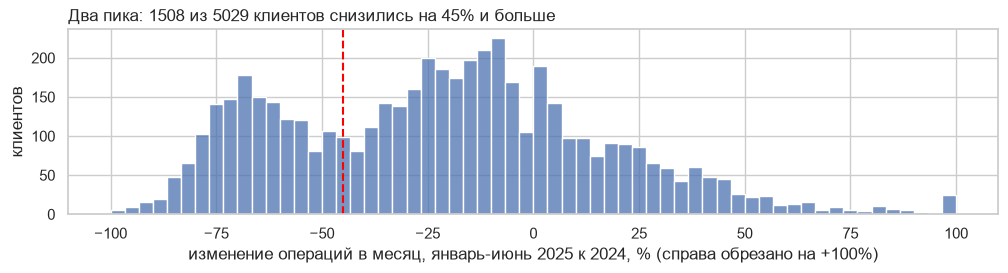

In [3]:
# изменение операций в месяц по клиентам; пунктир - порог 45%
fig, ax = plt.subplots(figsize=(12, 2.4))
sns.histplot(metric["change_all"].clip(upper=1) * 100, bins=60, ax=ax)
ax.axvline(-45, color="red", ls="--")
ax.set_xlabel("изменение операций в месяц, январь-июнь 2025 к 2024, % (справа обрезано на +100%)")
ax.set_ylabel("клиентов")
ax.set_title(f"Два пика: {int(metric['dropped'].sum())} из {metric.shape[0]} клиентов снизились на 45% и больше", loc="left")
plt.show()

У распределения два пика: около -70% и около -10%. Порог "снизился" поставлен на провал между ними (-45%). При пороге -40% и -50% группы для кампании остаются теми же, меняются только размеры (всего от 1465 до 1644 клиентов, 8.2).

### 4.3. Снижение - в массовом сегменте, сильнее всего у клиентов без приложения

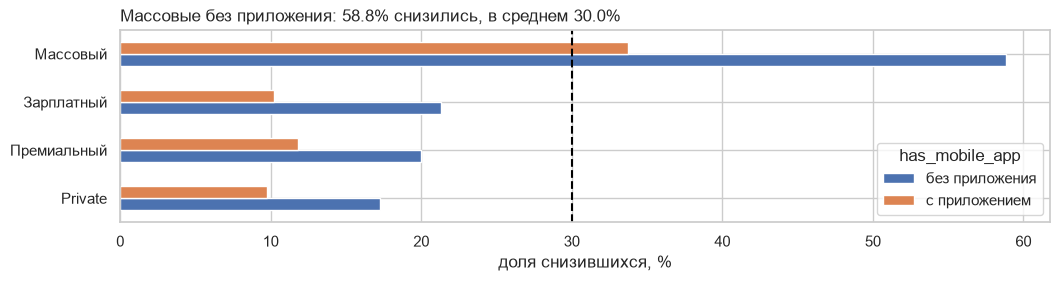

In [4]:
# доля снизившихся по сегменту и наличию приложения; пунктир - в среднем
seg = (metric.groupby(["segment", "has_mobile_app"], observed=True)["dropped"].mean() * 100).unstack()
seg = seg.rename(columns={False: "без приложения", True: "с приложением"})
seg = seg.loc[["Private", "Премиальный", "Зарплатный", "Массовый"]]

fig, ax = plt.subplots(figsize=(12, 2.5))
seg.plot.barh(ax=ax)
ax.axvline(metric["dropped"].mean() * 100, color="black", ls="--")
ax.set_xlabel("доля снизившихся, %")
ax.set_ylabel("")
ax.set_title(f"Массовые без приложения: {seg.loc['Массовый', 'без приложения']:.1f}% снизились, "
             f"в среднем {metric['dropped'].mean() * 100:.1f}%", loc="left")
plt.show()

Массовый сегмент - 1159 из 1508 снизившихся. Внутри каждого сегмента клиенты без приложения снижаются в 1.7-2.1 раза чаще (например, массовые 58.8% против 33.7%). Сильнее среднего снижаются также клиенты старше 60 лет и те, у кого зарплата в другом банке или источник не указан; город и пол почти не влияют (в Казани снизившихся больше только потому, что там больше массовых клиентов, 7).

### 4.4. Снизившиеся реже пользуются картой везде, включая оплату телефоном

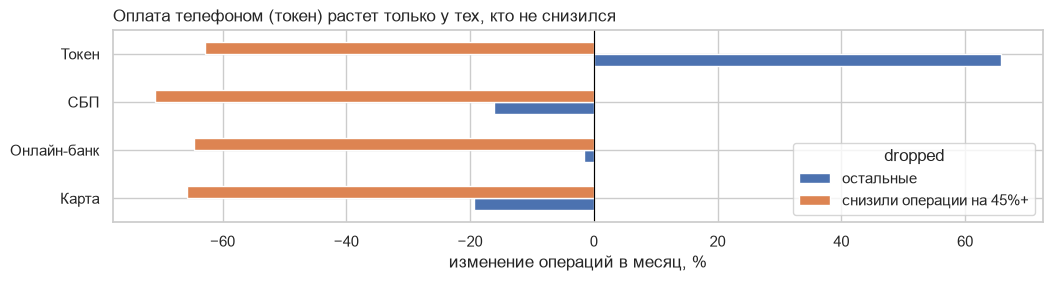

In [5]:
# изменение операций в месяц по каналам: январь-июнь 2025 к 2024, клиенты с полным 2024
t = txn[txn["client_id"].isin(full12.index)].copy()
t["dropped"] = t["client_id"].map(full12["dropped"]).astype(bool)
t["year"] = t["txn_datetime"].dt.year
ch = t.groupby(["dropped", "channel", "year"], observed=True).size().unstack("year")
ch = ((ch[2025] / 6) / (ch[2024] / 12) - 1) * 100
ch = ch.unstack("dropped").rename(columns={False: "остальные", True: "снизили операции на 45%+"})

fig, ax = plt.subplots(figsize=(12, 2.5))
ch.plot.barh(ax=ax)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("изменение операций в месяц, %")
ax.set_ylabel("")
ax.set_title("Оплата телефоном (токен) растет только у тех, кто не снизился", loc="left")
plt.show()

У снизившихся упали все каналы, в том числе токен (оплата телефоном) и СБП, и все категории трат - примерно на две трети. Доля отказов не изменилась. Значит, это не переход на другой способ оплаты внутри банка: клиент просто реже платит этой картой. У остальных клиентов часть операций по пластиковой карте ушла в токен.

### 4.5. Отдельно: часть клиентов почти перестала платить картой за развлечения

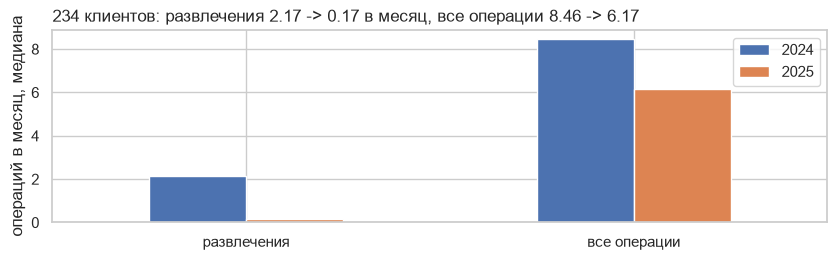

In [6]:
# группа 4: операции в месяц за развлечения и все операции, медианы
g4 = metric[metric["group"] == "4. ушли из развлечений"]
vals = pd.DataFrame({
    "2024": [g4["ent_2024"].median(), g4["base_all"].median()],
    "2025": [g4["ent_2025"].median(), g4["eval_all"].median()],
}, index=["развлечения", "все операции"])

fig, ax = plt.subplots(figsize=(10, 2.5))
vals.plot.bar(ax=ax, rot=0)
ax.set_ylabel("операций в месяц, медиана")
ax.set_title(f"{len(g4)} клиентов: развлечения {vals.loc['развлечения', '2024']:.2f} -> {vals.loc['развлечения', '2025']:.2f} в месяц, "
             f"все операции {vals.loc['все операции', '2024']:.2f} -> {vals.loc['все операции', '2025']:.2f}", loc="left")
plt.show()

Эти клиенты в целом снизились умеренно (меньше чем на 45%), но за развлечения почти перестали платить картой. По всем клиентам такого почти нет в других категориях (11-31 клиент на категорию против 274 в развлечениях). Среди них чаще обычного премиальные клиенты и Private - для них это отдельное предложение, про развлечения.

## 5. Группы для кампании

Все группы - только клиенты с согласием на коммуникацию, клиент попадает ровно в одну группу (правила не пересекаются). Медианы операций в месяц - 2024 и январь-июнь 2025.

In [7]:
# группы: размер и медианы
groups = metric[metric["group"].notna()].groupby("group").agg(
    клиентов=("change_all", "size"),
    операций_2024=("base_all", "median"),
    операций_2025=("eval_all", "median"),
    изменение=("change_all", "median"),
    возраст=("age", "median"),
)
groups.round(2)

,клиентов,операций_2024,операций_2025,изменение,возраст
group,,,,,
1. массовые без приложения,535,5.00,1.50,-0.67,59.0
2. массовые с приложением,481,5.50,1.83,-0.66,49.0
"3. зарплатные, премиальные и Private",301,6.00,2.17,-0.64,55.0
4. ушли из развлечений,234,8.46,6.17,-0.28,50.0


**1. Массовые без приложения (535)** - массовый сегмент, нет приложения, операций меньше на 45% и больше. Самые возрастные (медиана 59 лет), к маю-июню у 54.6% операций почти не осталось. Предложение: установить приложение и подключить оплату телефоном, с поддержкой в отделении.

**2. Массовые с приложением (481)** - массовый сегмент, есть приложение, операций меньше на 45% и больше. Похоже на перенос трат на карту другого банка - кешбэк в повседневных категориях и напоминание в приложении.

**3. Зарплатные, премиальные и Private (301)** - не массовый сегмент, операций меньше на 45% и больше. Активнее остальных (6.00 операции в месяц в 2024) - персональный контакт менеджера и выяснение причины.

**4. Ушли из развлечений (234)** - в 2024 платили за развлечения хотя бы раз в месяц, в 2025 на 80% и больше реже, в целом снизились меньше чем на 45%. Развлечения 2.17 -> 0.17 в месяц - кешбэк или скидки партнеров на досуг.

## 6. Кого не включаем и почему

В кампании 1551 из 5612 клиентов. Не включаем: 583 - карта открыта с 2024-10, в 2024 меньше 3 месяцев операций, сравнить не с чем; 186 снизившихся и 40 ушедших из развлечений без согласия на коммуникацию - писать им нельзя; 5 снизившихся с неизвестным сегментом (в выгрузке у клиента две записи с разным сегментом); 3247 не снизились - кампания им не нужна. Отдельно не включены 388 клиентов, ушедших из банка: их уже нет в справочнике действующих клиентов.

## 7. Что проверили и что не подтвердилось

| гипотеза | результат |
|---|---|
| в Казани особая проблема | нет: снизившихся 38.5% против 30.0%, но это состав - внутри массового сегмента в Казани 41.9% против 44.3% в других городах |
| переход с карты на оплату телефоном | нет: у снизившихся токен упал на 62.7%, растет (+64.6%) только у не снизившихся |
| картам стали чаще отказывать | нет: доля отказов у снизившихся 1.88% в 2024 и 1.95% в 2025 |
| до нуля к лету дошла одна подгруппа | нет: "почти ноль в мае-июне" 42.3-55.0% по подгруппам при 47.5% в среднем |
| выводы зависят от возвратов | нет: изменение с возвратами и без совпадает, Спирмен 0.998 |

## 8. Приложение

### 8.1. Сводка журнала изменений

Полный журнал (19 решений) - в cleaning_log.csv.

| поле | что найдено | строк | что сделано |
|---|---|---|---|
| txn_datetime | нет времени (потеря случайная) | 49623 | 00:00:00 + флаг datetime_valid_hours |
| monthly_income | доход в тысячах / код -999 | 173 / 53 | ×1000 / пропуск |
| city, category | разные написания / категория не по MCC | 1619, 51117 / 1599 | нормализация / исправлено по MCC |
| все поля | дубли клиентов / операций | 55 / 1500 | удалено, при расхождении - копия со временем или пропуск в segment, city |
| monthly_income, satisfaction_score, amount | пропуски / выше границы IQR | 606, 3285 / 49866, 401 | оставлено, выбросы с флагами |
| txn_datetime, client_id | вне периода / не из справочника | 84 / 30440 | не учитываются |

### 8.2. Методика

- База: операций в 2024 / полных месяцев карты в 2024 (с месяца после открытия карты; разгона после открытия нет). Оцениваемый период: операций в январе-июне 2025 / 6. Изменение = оцениваемый / база - 1, только при базе от 3 месяцев (карта до 2024-09).
- Порог -0.45 - самое низкое место между пиками (интервал -0.5..-0.45, 124 клиента). При -0.4 и -0.5 группы 571/517/349/207 и 509/446/260/250, все больше 150.
- Сезон: к тем же месяцам 2024 медиана изменения -0.148 вместо -0.212, порядок клиентов тот же (Спирмен 0.958).
- Ушли из развлечений: в 2024 от 1 операции в месяц, в 2025 на 80% и больше меньше, изменение больше -0.45.
- Медианы вместо средних: у операций длинный правый хвост.

### 8.3. Использование ИИ
Использовался как помощник и консультант: правил слишком топорный код, строил некоторые графики по примеру, помогал взглянуть на данные с другой стороны в ситуациях, когда исследование заходило в тупик. Также правил и проверял места, где я был не уверен в правильности выводов, которые могли формироваться на основе неправильных расчетов или ошибочных метрик. По ходу работы замечались откровенные ошибки и неточности ассистента, которые стопорили работу: проценты без явного знаменателя, неверные выводы и предложение удалить возвраты для метрики с суммой 
<!-- 3–5 строк: для чего использовали и что проверили сами. -->